# Historical Aave V3 / Morpho V1 Versus Treasury Bills

**Historical appendix.** These are older contracts, not current Aave V4 or Morpho V2 quotes. [Current-product comparison](01_usdc_yield_and_liquidity.ipynb).

**How much extra income accompanied the withdrawal risk?**

Over **866 days**, the three selected DeFi positions finished **USD 58–USD 85 ahead of SGOV per USD 10,000**, after the stated base execution costs. The annualized advantage was **0.23–0.34 percentage points**. Costs or a small additional loss in the final USDC value could erase that premium.

The liquidity evidence is a separate finding: interest can continue accruing while available cash becomes scarce. This is a retrospective case study, not a complete valuation of credit, contract or liquidity risk.

**Study period:** 1 June 2024 00:00–15 October 2026 00:00 UTC. **Products:** Aave V3 Ethereum Core; Morpho Steakhouse USDC V1; Morpho Gauntlet USDC Prime V1. **Treasury proxy:** iShares 0–3 Month Treasury Bond ETF (SGOV).

[Reproduce](../README.md#reproduce) · [data sources](../docs/DATA_SOURCES.md) · [benchmark and cost design](../docs/TREASURY_COMPARISON.md) · [detailed liquidity appendix](02_liquidity_details.ipynb).

## 1. What the comparison measures

All positions start with **10,000 units of capital**. DeFi return comes from the original on-chain income indices or fee-aware vault share values. Treasury return comes from SGOV NAV changes **plus reinvested distributions**, with fund expenses already reflected. We do not compare DeFi APYs with an uninvested Treasury yield quote.

### Key assumptions

- **Currency:** 1 USDC = USD 1 at entry and exit. This is conditional on par conversion, not a measured USD redemption history. A separate terminal-haircut sensitivity shows how that assumption matters.
- **Identical valuation period:** use the original UTC anchors. SGOV uses the latest preceding valuation: 31 May 2024 through 14 October 2026. Weekends retain the last published NAV; no future NAV or invented weekend price is used. These are existing-position valuations, not a Saturday purchase simulation.
- **Treasury proxy:** SGOV invests in short-term Treasury securities but is an ETF, not a directly held bill ladder. Its NAV is not a guaranteed executable bid. Distributions are hypothetically reinvested at ex-date NAV; actual cash payment occurs later.
- **Costs:** entry costs reduce the capital invested; exit costs reduce the ending balance. Broker commission is assumed zero. Costs are scenarios, not reconstructed historical trades. Fund and vault fees are already reflected and are not deducted twice. Token rewards and taxes are excluded.

The Treasury extension was documented after the DeFi results but before computing this benchmark comparison. [Original design](../docs/PROTOCOL.md) · [extension](../docs/TREASURY_COMPARISON.md).

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'treasury_analysis.py').exists(), 'Run from this study or its notebooks folder.'
sys.path.insert(0, str(ROOT))
from treasury_analysis import compare, SCENARIOS
from treasury_figures import build, SHORT
results, costs, joined, treasury, panel, daily, eth = compare()
figures = build((results, costs, joined, treasury, panel, daily, eth))

## 2. Most of the yield was available from Treasury bills

The left panel shows extra accounting income before execution costs; the right panel subtracts the base cost assumptions. A declining excess-income curve means SGOV was catching up, not necessarily that the DeFi balance was falling.

**Base costs per side:** DeFi USD 10 fixed plus 5 basis points (0.05%) conversion spread; SGOV 0.5 basis point (0.005%) execution spread. These are explicit illustrative assumptions. At USD 10,000, entry and exit costs plus foregone growth reduce DeFi terminal wealth by about USD 32, versus about USD 1 for SGOV.

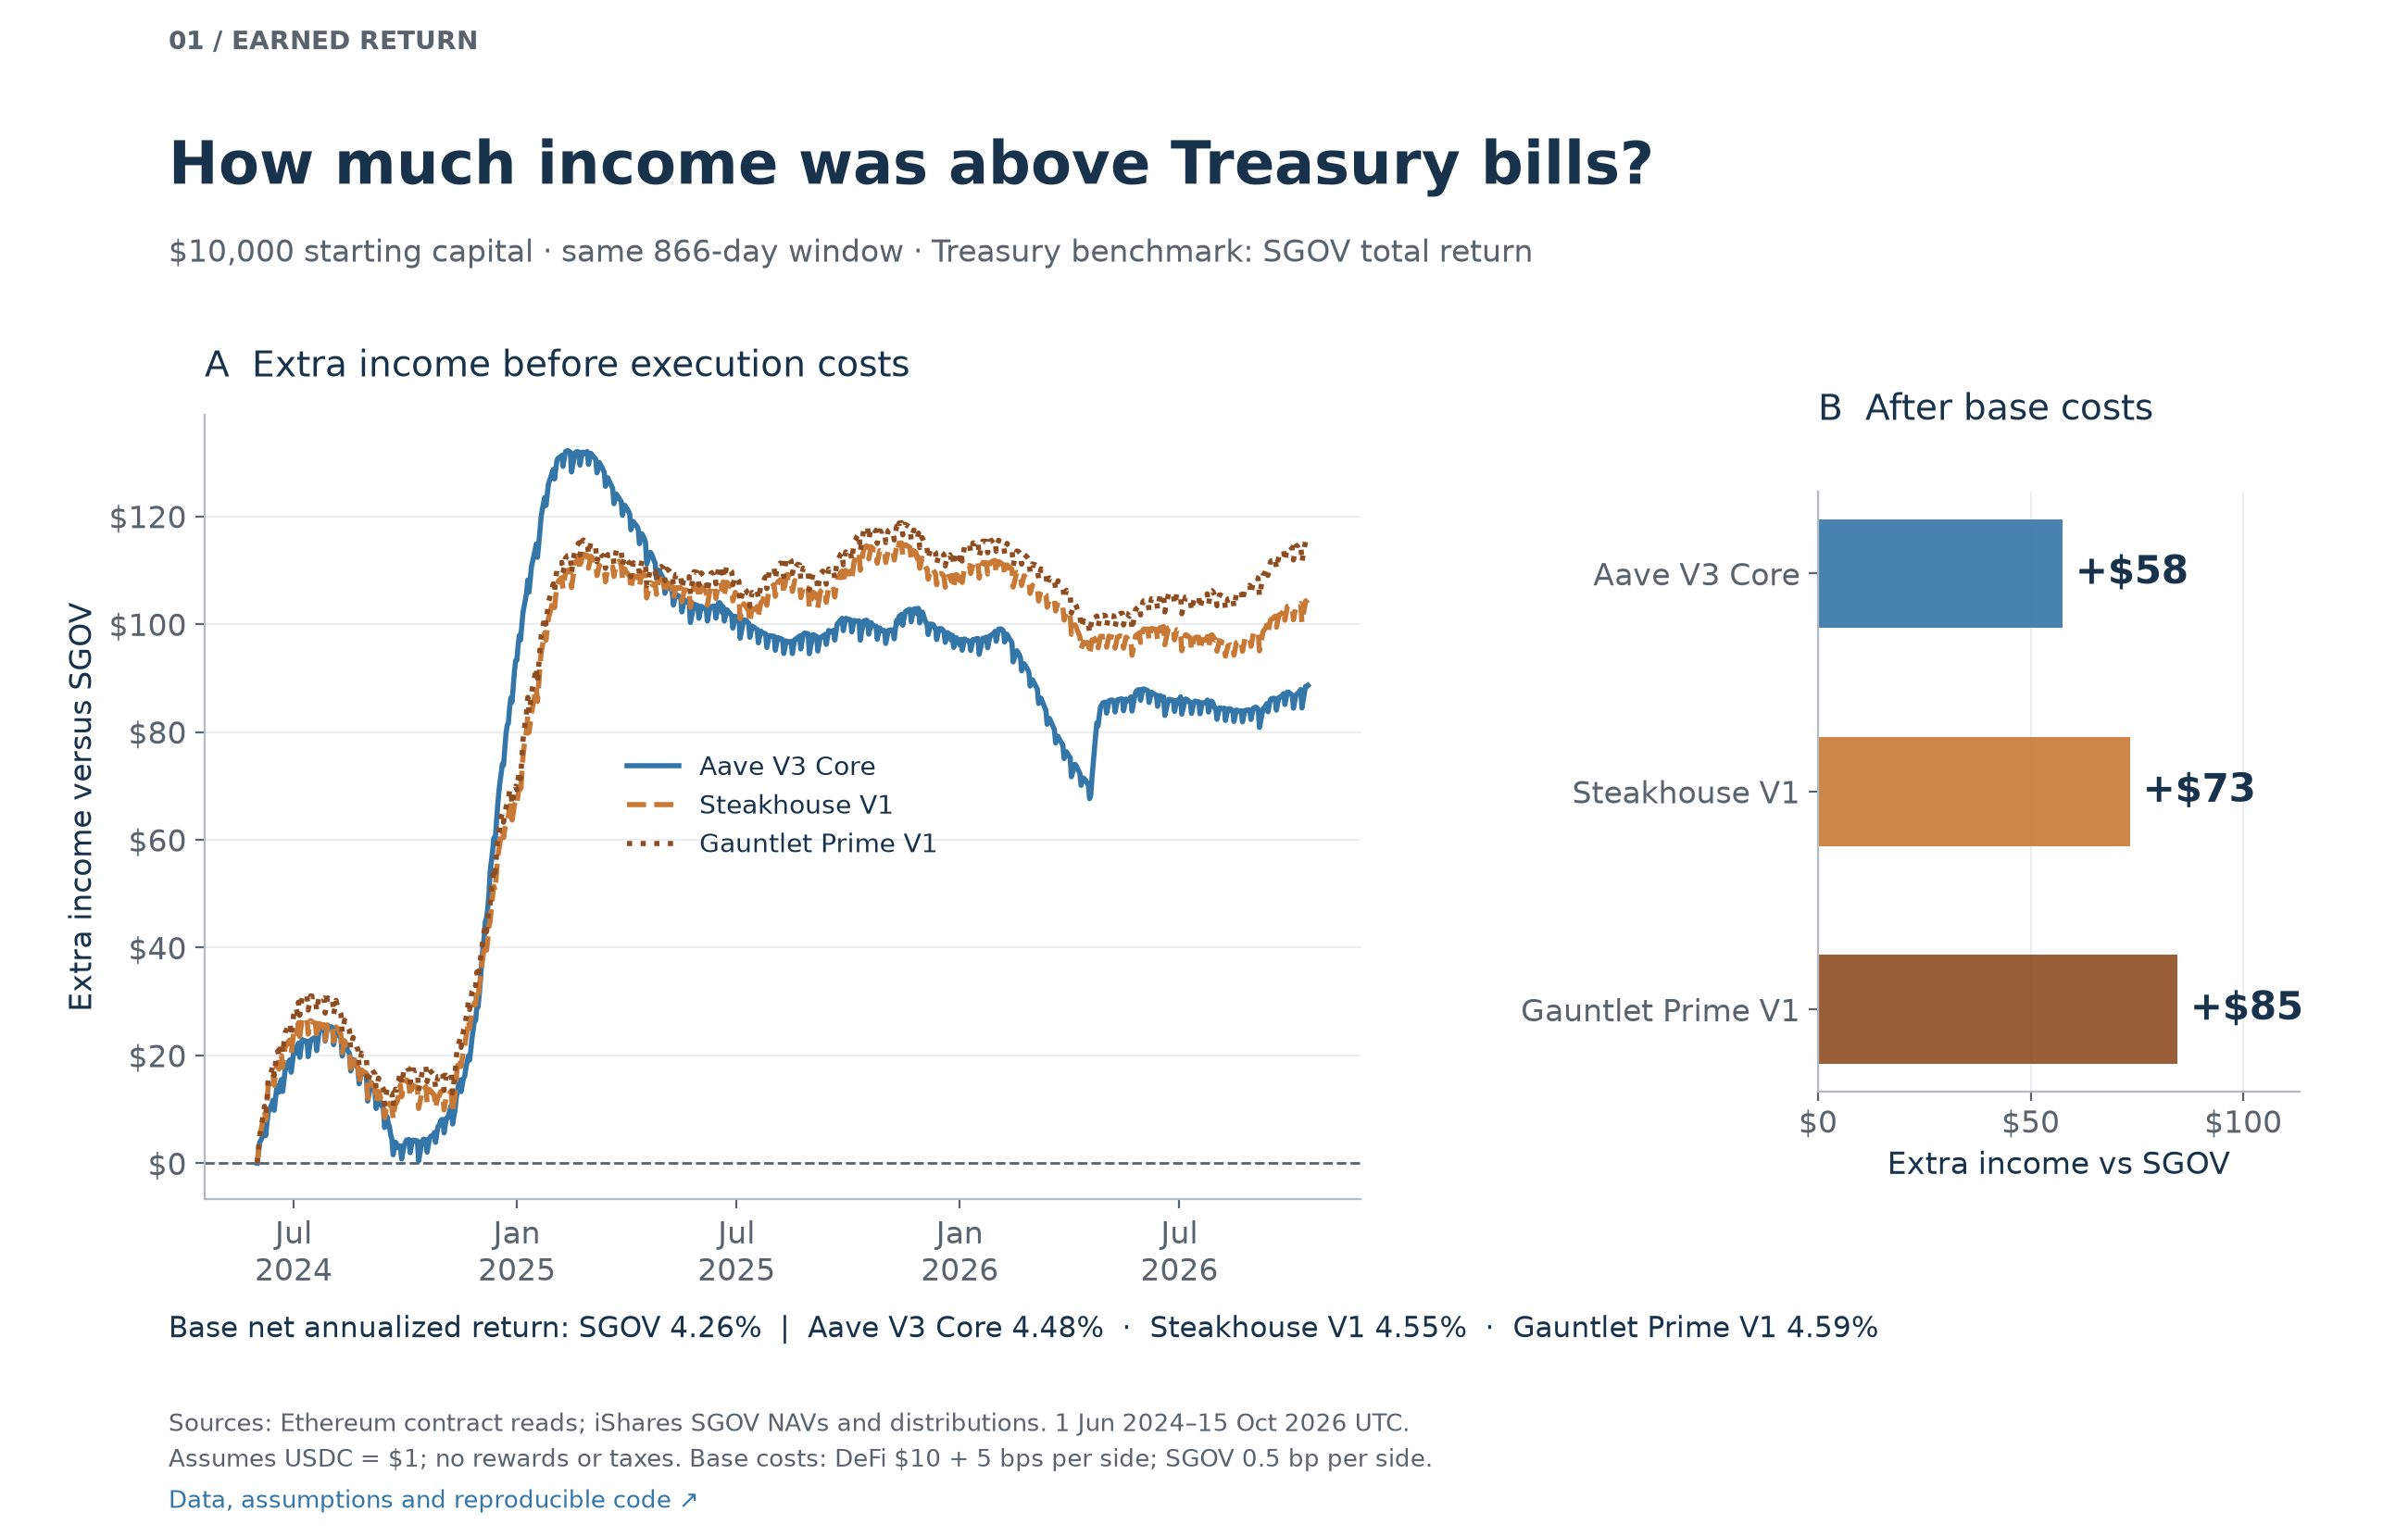

In [2]:
display(Image(filename=str(figures[0]), alt='Matched-period extra income versus SGOV and net excess income of 58 to 85 dollars per 10000 after base execution costs.'))

**Sources:** [historical Ethereum reads and exact contracts](../docs/DATA_SOURCES.md) · [iShares SGOV data](https://www.ishares.com/us/products/314116/ishares-0-3-month-treasury-bond-etf) · [Treasury input hashes](../data/treasury_manifest.json).

In [3]:
table = results.loc[['sgov','aave','steakhouse_v1','gauntlet_v1'], ['gross_annualized_pct','net_annualized_pct','net_profit','extra_vs_sgov','excess_annualized_pp']].copy()
table.index = table.index.map(SHORT)
table.columns = ['Before execution costs (%/yr)','Base costs (%/yr)','Net profit on 10,000 ($)','Extra vs SGOV ($)','Annualized advantage (pp)']
display(table.style.format({table.columns[0]:'{:.2f}',table.columns[1]:'{:.2f}',table.columns[2]:'{:,.2f}',table.columns[3]:'{:+.2f}',table.columns[4]:'{:+.3f}'}))

,Before execution costs (%/yr),Base costs (%/yr),"Net profit on 10,000 ($)",Extra vs SGOV ($),Annualized advantage (pp)
product,,,,,
Treasury ETF · SGOV,4.26,4.26,"1,039.50",+0.00,+0.000
Aave V3 Core,4.61,4.48,"1,097.01",+57.51,+0.229
Steakhouse V1,4.68,4.55,"1,112.87",+73.37,+0.291
Gauntlet Prime V1,4.72,4.59,"1,124.03",+84.52,+0.336


The **total** 4.5–4.6% net DeFi return is not the premium for accepting DeFi risk: SGOV earned about 4.26% annualized after its assumed trading costs. The incremental compensation in this sample was substantially smaller. It does not by itself establish whether a particular investor was adequately compensated.

## 3. Costs and exit value can change the conclusion

| Assumed scenario | DeFi fixed cost, each side | DeFi conversion spread, each side | SGOV spread, each side |
|---|---:|---:|---:|
| Low | USD 5 | 0 bps | 0.5 bp |
| Base | USD 10 | 5 bps | 0.5 bp |
| High | USD 50 | 25 bps | 2.5 bps |

The left panel varies execution costs. The right applies an **additional** reduction to the final USDC value under base costs. The break-even haircut is an arithmetic threshold, not an estimated probability, a forecast loss, or an assumption that SGOV has no risks.

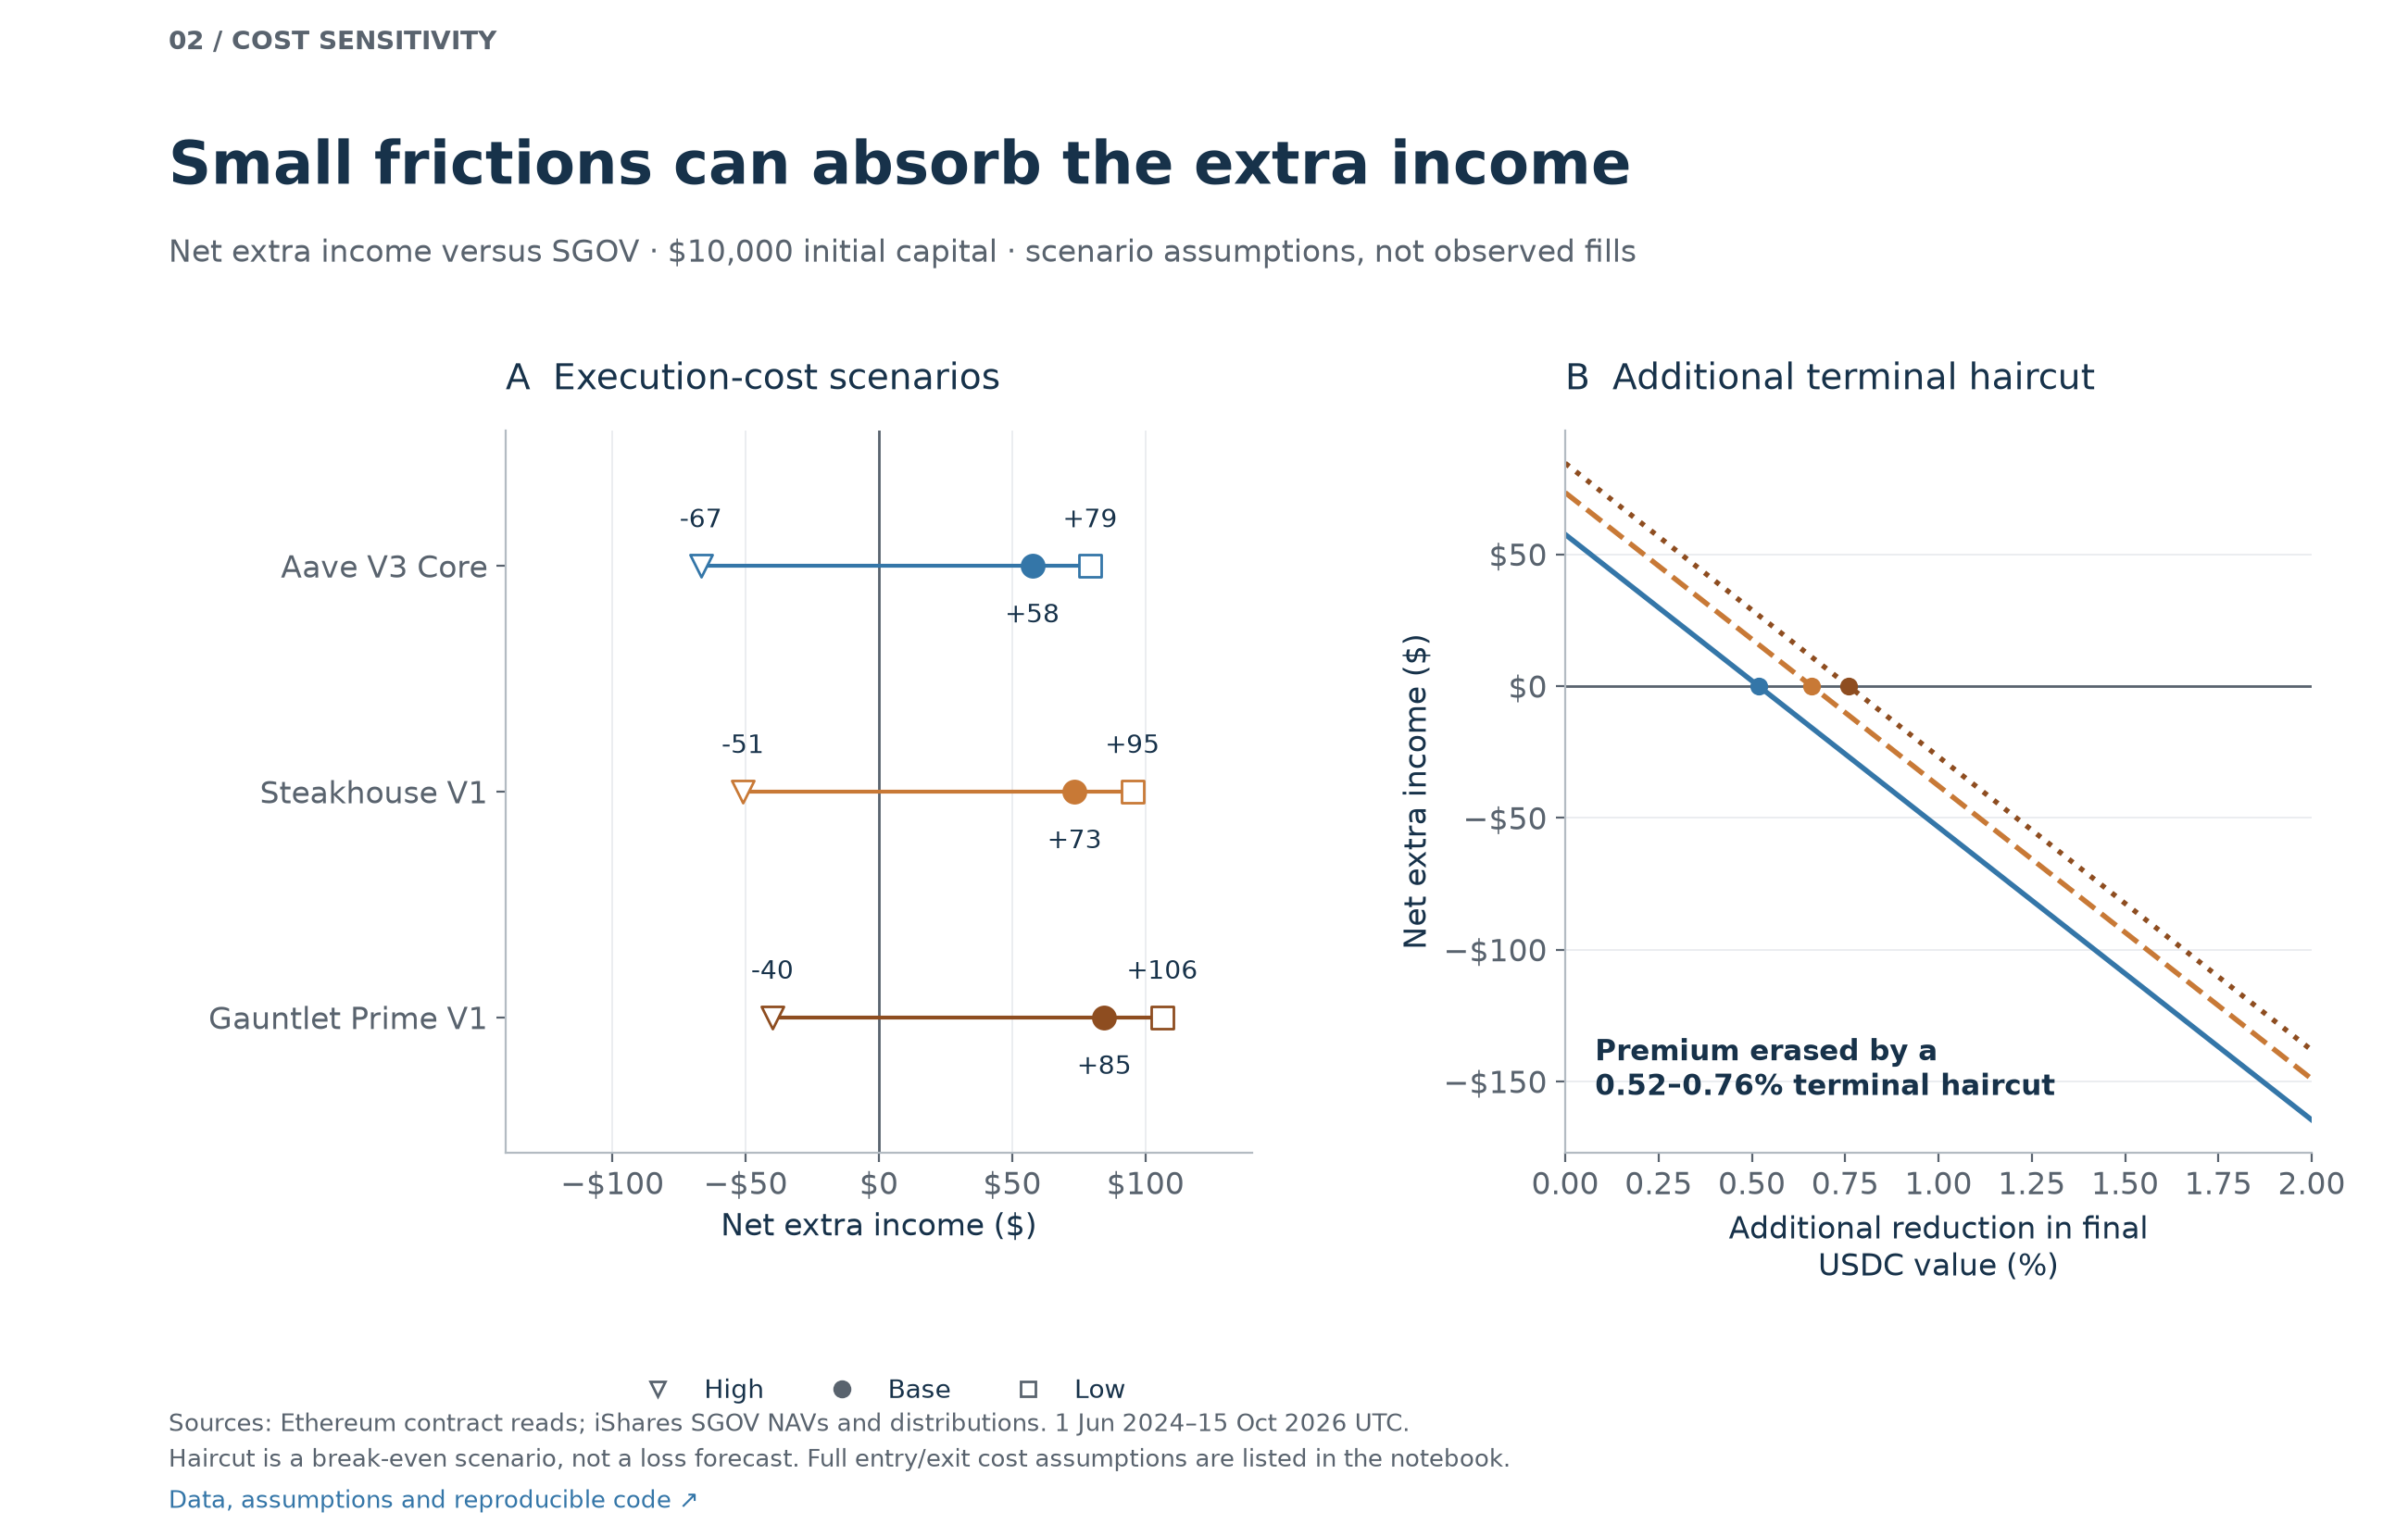

In [4]:
display(Image(filename=str(figures[1]), alt='Cost scenarios and terminal USDC haircut sensitivity show the modest premium can disappear; break-even haircuts are 0.52 to 0.76 percent.'))

**Sources:** [historical Ethereum reads and exact contracts](../docs/DATA_SOURCES.md) · [iShares SGOV data](https://www.ishares.com/us/products/314116/ishares-0-3-month-treasury-bond-etf) · [Treasury input hashes](../data/treasury_manifest.json). · [all cost and capital-size scenarios](../reports/treasury_cost_sensitivity.csv).

In [5]:
size = costs[costs.scenario.eq('Base') & costs['product'].ne('sgov')].pivot(index='product', columns='initial_capital', values='extra_vs_sgov').reindex(['aave','steakhouse_v1','gauntlet_v1'])
size.index = size.index.map(SHORT)
size.columns = [f'${v:,.0f} starting capital' for v in size.columns]
display(Markdown('**Net extra income versus SGOV under base costs ($), by position size**'))
display(size.style.format('{:+,.2f}'))

**Net extra income versus SGOV under base costs ($), by position size**

,"$1,000 starting capital","$10,000 starting capital","$100,000 starting capital"
product,,,
Aave V3 Core,-13.26,+57.51,+765.16
Steakhouse V1,-11.68,+73.37,+923.86
Gauntlet Prime V1,-10.58,+84.52,"+1,035.53"


At USD 10,000, all three positions outperform SGOV under the base assumptions, but all three underperform it under the high-cost assumptions. Under base costs, a further **0.52–0.76% reduction in final USDC value** erases the advantage. Smaller positions are more sensitive to fixed costs. None of these calculations estimates the likelihood of a haircut.

## 4. A return comparison is not a cash-access comparison

The capacity curve shows the fraction of **867 daily snapshots** with enough available cash to meet different collective withdrawal requests. It measures static historical capacity, not a default probability or observed transaction-failure rate.

The April 2026 panel shows a separate, exploratory example selected after finding the sample minimum. Aave's USDC cash fell to **6,519 USDC**, against about **2.10 billion USDC of claims**. That observation was checked through two independent RPC providers. The timing coincided with the documented rsETH incident; the analysis does not claim a realized USDC principal loss or attribute every cash movement to the incident.

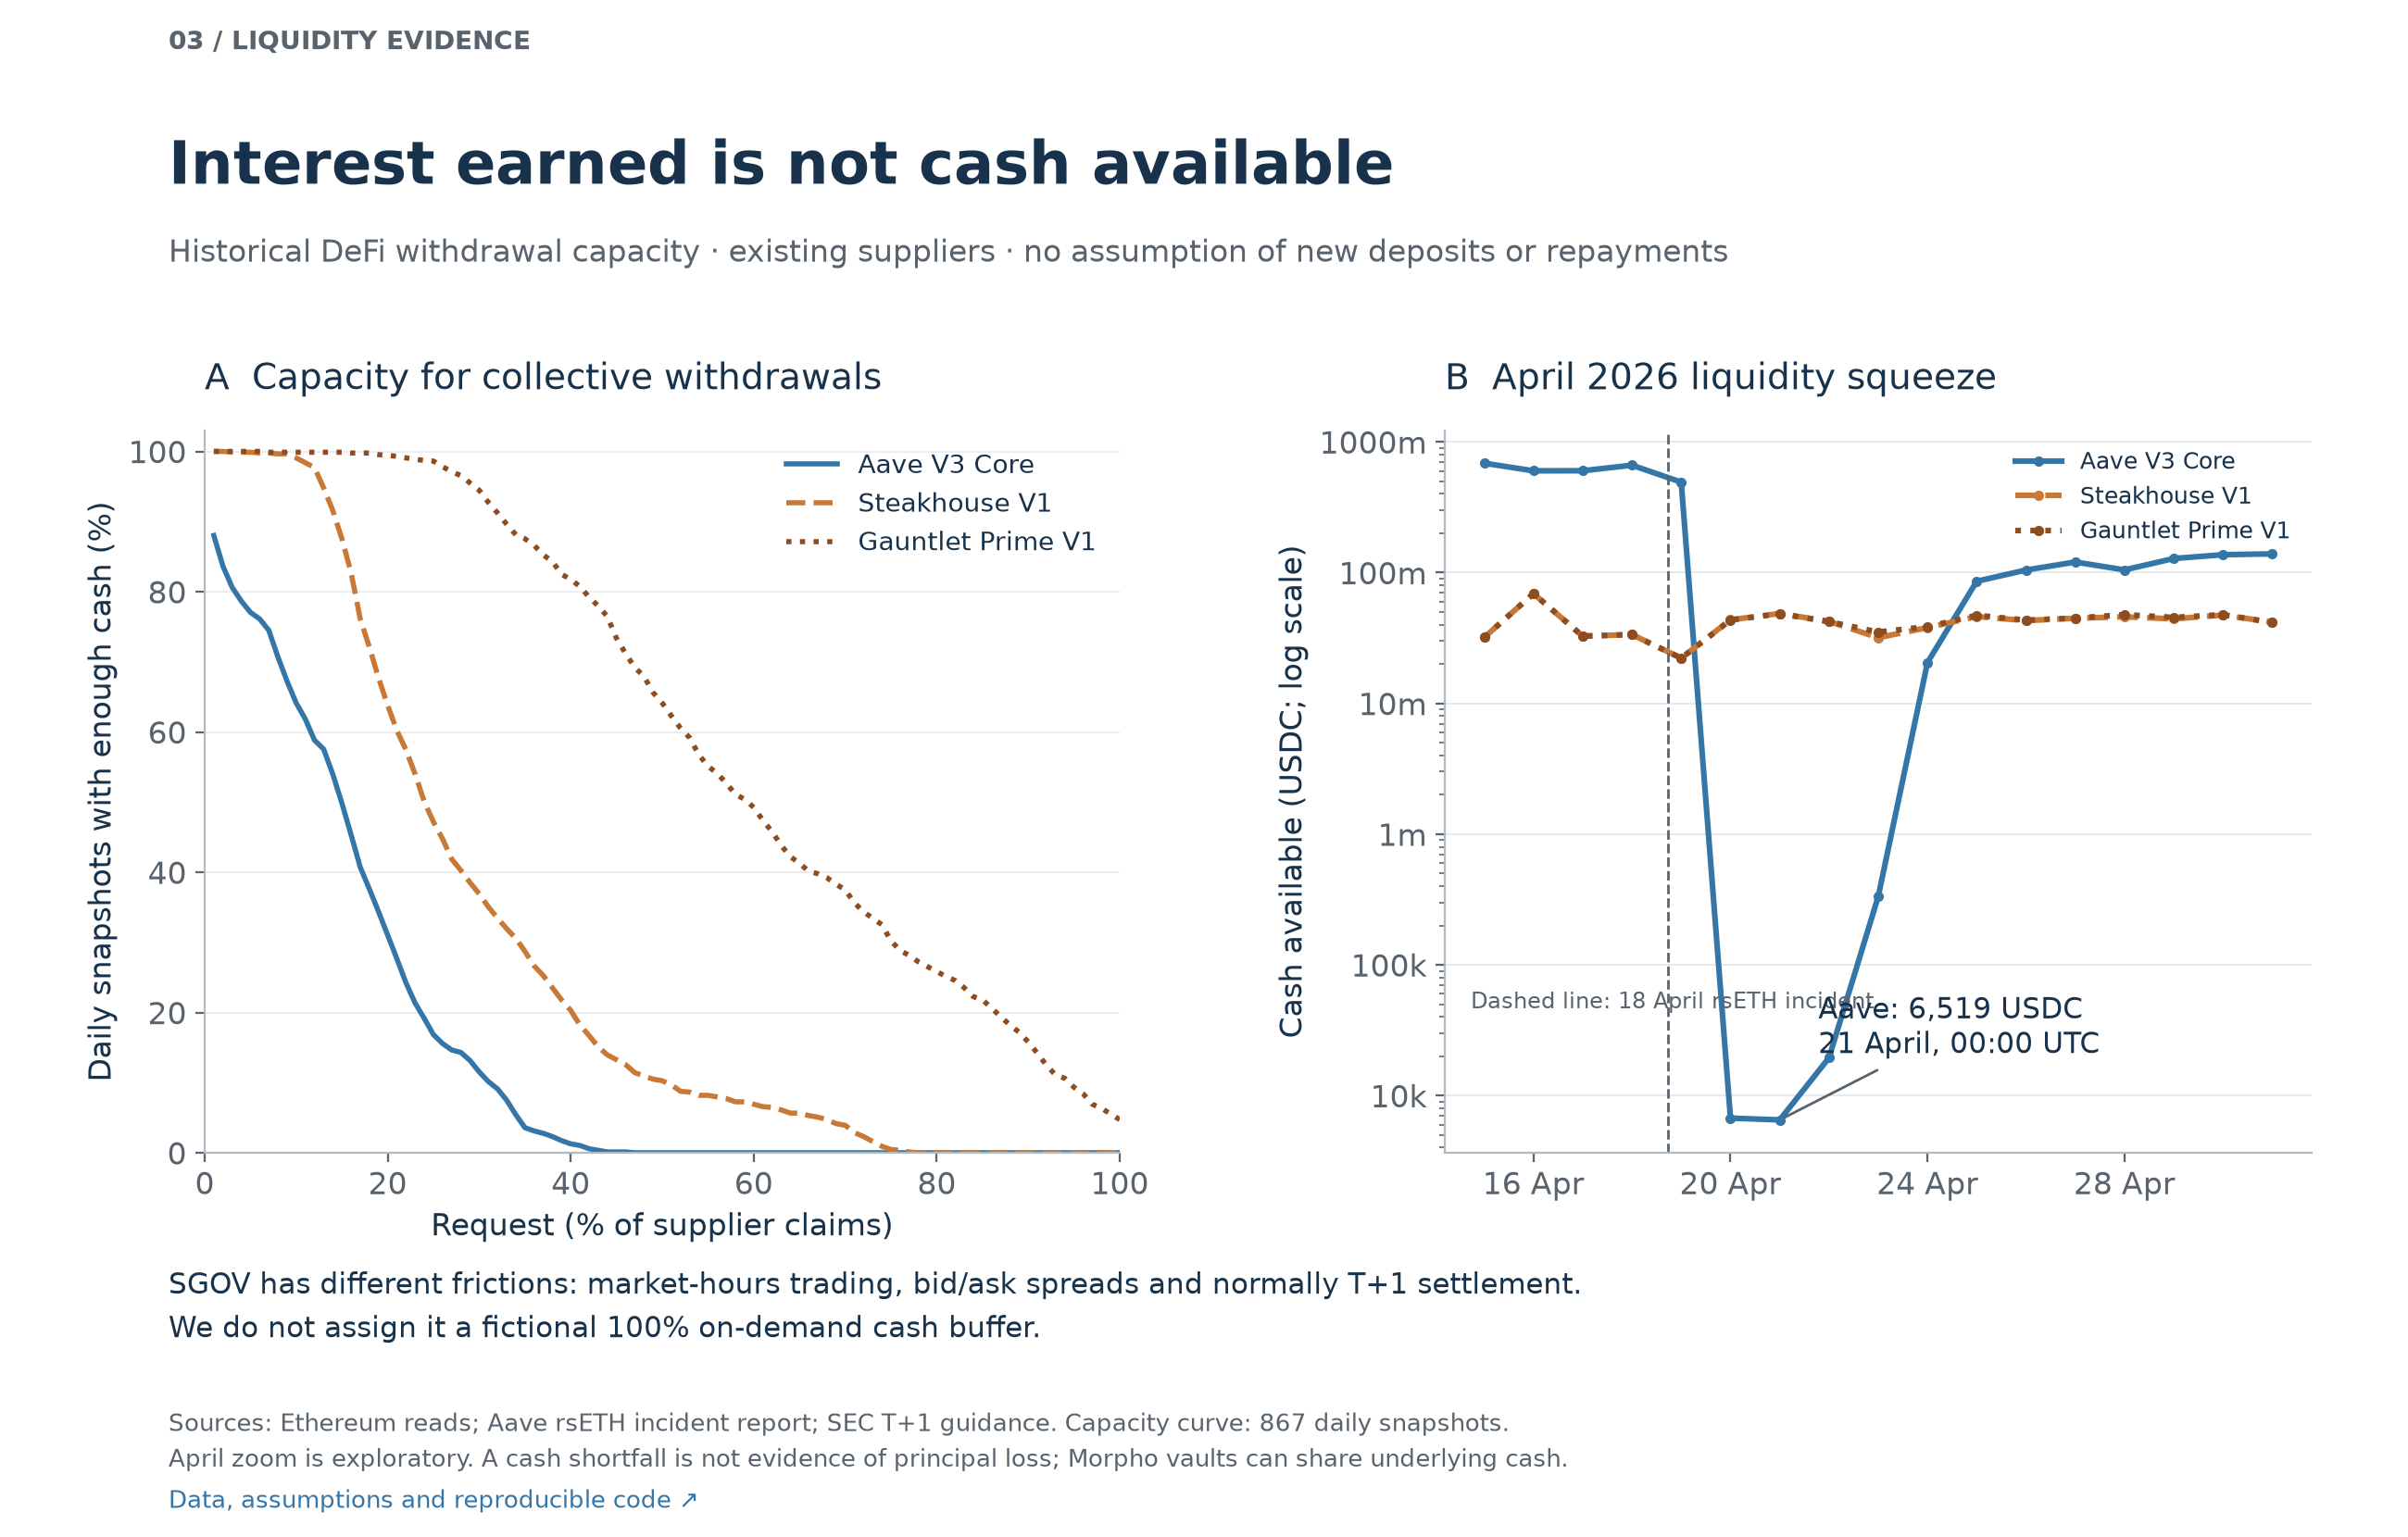

In [6]:
display(Image(filename=str(figures[2]), alt='DeFi withdrawal-capacity curves and the April 2026 Aave liquidity squeeze; these measure available cash, not principal losses.'))

**Sources:** [historical Ethereum reads and exact contracts](../docs/DATA_SOURCES.md) · [iShares SGOV data](https://www.ishares.com/us/products/314116/ishares-0-3-month-treasury-bond-etf) · [Treasury input hashes](../data/treasury_manifest.json). · [Aave incident report](https://governance.aave.com/t/rseth-incident-report-april-20-2026/24580) · [independent minimum check](../data/raw/crosschecks/aave_minimum_1rpc.io.json).

**SGOV has different exit constraints.** ETF shares trade during market hours, incur bid/ask spreads, and generally settle one business day after sale. NAV is not an offer to redeem instantly at that price. We have not estimated its historical transaction capacity and do not assign it a fictional 100% on-demand cash buffer. Direct bills bought through TreasuryDirect have their own holding and transfer rules. [SEC settlement guidance](https://www.investor.gov/introduction-investing/general-resources/news-alerts/alerts-bulletins/investor-bulletins/new-t1-settlement-cycle-what-investors-need-know-investor-bulletin) · [TreasuryDirect rules](https://www.treasurydirect.gov/marketable-securities/selling-marketable-securities/).

**Crypto drawdown is not a sufficient liquidity indicator.** In the exploratory 90-day ETH drawdown analysis, Aave had more relative cash during deeper drawdowns, while the two Morpho vaults showed little monotonic relationship. Repayments can improve cash availability even as collateral risk rises. [Separate drawdown diagnostic](../reports/DRAWDOWN_DIAGNOSTIC.md).

The selected Morpho vaults generally had larger cash buffers than Aave, but can draw on the same underlying market cash. Their capacities cannot be added as independent liquidity. This study concerns these **V1** contracts; it does not evaluate the later V2 products.

## 5. What we can conclude

1. **The excess income was modest.** After base costs, USD 10,000 earned USD 58–USD 85 more than the Treasury ETF over 866 days. Higher costs reversed that comparison.
2. **Accrued income and accessible cash are different outcomes.** A smooth earnings curve can coexist with a severe withdrawal-liquidity squeeze.
3. **The evidence does not price all risks.** Contract failures, collateral losses, USDC depegging, tax treatment, wallet execution and future liquidity needs remain outside this conditional return comparison. Two surviving Morpho vaults are not representative of all vaults. Daily observations are dependent; no statistical-significance claim is made.

A useful next study would measure actual exit proceeds and time-to-cash, include rewards and a broader vault sample, and evaluate Morpho V2 over its own common period. The present finding supports a focused question: **is the small incremental income enough for the exit constraints an investor is accepting?**

## Sources and reproducibility

- [Source catalogue and exact contracts](../docs/DATA_SOURCES.md); [original raw-data manifest](../data/manifest.json); [Treasury extract and hashes](../data/treasury_manifest.json).
- [Independent monthly Treasury-return checks](../reports/treasury_monthly_checks.csv), covering 28 months. The largest discrepancy is below 0.001 percentage point; independent high-precision compounding also matches the endpoint result.
- [Reproduce this notebook](../README.md#reproduce); [cost calculations](../treasury_analysis.py); [figure builder](../treasury_figures.py).
- [Detailed historical appendix](02_liquidity_details.ipynb) preserves the three preselected sell-offs and the original accounting analysis.
- [LinkedIn summary figure](../figures/treasury/linkedin_treasury_comparison.png) is an export for review, not a published post.

This notebook executes offline from the saved numerical inputs and verified Ethereum snapshots. Recollecting issuer data is optional and separately documented.